$\text{Extracting the data from the CSV files from the JPL NASA Horizons application}$

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


#This class contains the initial position and velocity of the celestial body:

class body:
    def __init__(self,name,mass,pos,vel):
        self.name=name
        self.mass=mass
        self.pos=np.array(pos,dtype=float)
        self.vel=np.array(vel,dtype=float)
        
# Data from the NASA Horizons data :


b1 = body("Sun", 1988410e24, np.array([-1.602325979919614E+05,-7.005062866580029E+05 , -2.888835766883729E+05]), np.array([1.031902521729396E-02, 4.449029074274385E-03, 1.684369200411074E-03]))

b2 = body("Mercury", 3.302e23, np.array([5.005945338170964E+07, 9.740919593283530E+06, 8.434890081924666E+04]), np.array([-1.867497438964642E+01, 4.357107773137023E+01, 2.521169409511218E+01]))

b3 = body("Venus", 48.685e23, np.array([8.302432525358570E+07,6.425708656179664E+07 , 2.367777884417082E+07]), np.array([-2.247968325249581E+01,  2.391654264351647E+01,  1.218439937840489E+01]))

b4 = body("Earth", 5.97219e24, np.array([1.197286311109774E+08,  7.982463976381977E+07,  3.461601209038475E+07]), np.array([-1.805688133808997E+01,  2.195386395433621E+01,  9.517041959974549E+00]))

b5 = body("Mars", 6.4171e23, np.array([-3.932279784924307E+07,  2.124476993615854E+08,  9.853347780953923E+07]), np.array([-2.297156296757593E+01, -1.971991104355783E+00, -2.850371983145413E-01]))

b6 = body("Jupiter",18.9819e26 , np.array([ -5.469428826456959E+08,  5.251793803450833E+08,  2.384273303310489E+08]), np.array([-9.636786632066425E+00, -7.784841955694026E+00, -3.102163240189204E+00]))


bodies=[b1,b2,b3,b4,b5,b6]


N=len(bodies)

def acc(mass,pos):

    
    a=np.zeros((len(bodies),3))

    for i in range(len(bodies)):
        for j  in range(len(bodies)):

            
            if i!=j:
                G = 6.67430e-20
                
                r=pos[i]-pos[j]

                ax=-((G*mass[j]*r[0])/(np.linalg.norm(r)**3))
                ay=-((G*mass[j]*r[1])/(np.linalg.norm(r)**3))
                az=-((G*mass[j]*r[2])/(np.linalg.norm(r)**3))

                a[i]+=np.array([ax,ay,az])

    return a
                

            
def eq_o_mot(t,state):
    N=len(bodies)
    pos=state[:3*N].reshape(N,3)
    vel=state[3*N:].reshape(N,3)

    m=np.array([])
    for i in range(N):
        m=np.append(m,bodies[i].mass)

    ac=acc(m,pos)

    return np.concatenate((vel.flatten(),ac.flatten()))


initial_pos=np.array([])
initial_vel=np.array([])

for i in range(N):
    initial_pos=np.append(initial_pos,bodies[i].pos)
    initial_vel=np.append(initial_vel,bodies[i].vel)

state0=np.concatenate((initial_pos,initial_vel))

days=50

t_span = (0, days*24*3600)

t_eval = np.linspace(0, days*24*3600,50 )
    
sol=solve_ivp(eq_o_mot,t_span,state0,method='DOP853',t_eval=t_eval)



        

In [2]:
sol.y

array([[-1.60232598e+05, -1.59323204e+05, -1.58414546e+05, ...,
        -1.18492377e+05, -1.17630849e+05, -1.16770574e+05],
       [-7.00506287e+05, -7.00113417e+05, -6.99719284e+05, ...,
        -6.80613021e+05, -6.80158680e+05, -6.79703106e+05],
       [-2.88883577e+05, -2.88734801e+05, -2.88585469e+05, ...,
        -2.81246911e+05, -2.81070243e+05, -2.80893008e+05],
       ...,
       [-9.63678663e+00, -9.62405989e+00, -9.61131571e+00, ...,
        -9.02029600e+00, -9.00678383e+00, -8.99325569e+00],
       [-7.78484196e+00, -7.79706466e+00, -7.80926913e+00, ...,
        -8.33933841e+00, -8.35068687e+00, -8.36201635e+00],
       [-3.10216324e+00, -3.10771202e+00, -3.11325340e+00, ...,
        -3.35484216e+00, -3.36003533e+00, -3.36522076e+00]],
      shape=(36, 50))

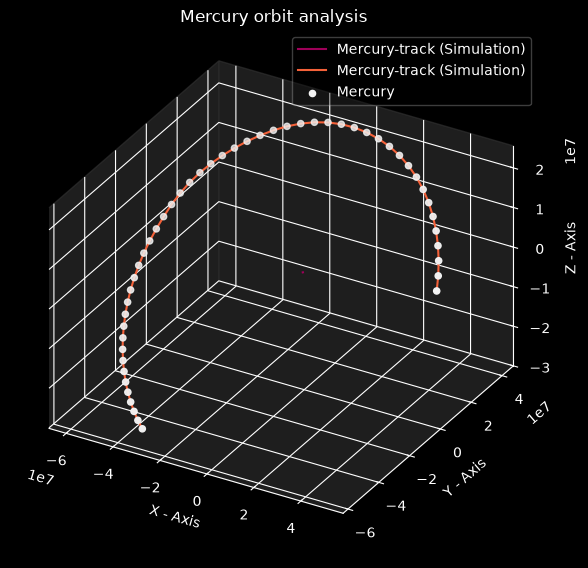

In [3]:
with plt.style.context("dark_background"):

    fig=plt.figure(figsize=(6,6))
    ax=fig.add_subplot(projection="3d")
    ax.set_title("Mercury orbit analysis")
    ax.set_xlabel("X - Axis")
    ax.set_ylabel("Y - Axis")
    ax.set_zlabel("Z - Axis")
    # Set the background panel colors with a low alpha (e.g., 0.1 for 10% opacity)
    # Format is (Red, Green, Blue, Alpha)
    ax.xaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.yaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.zaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.set_proj_type('ortho')



    ax.plot(sol.y[0],sol.y[1],sol.y[2],color="#9E0059",label="Mercury-track (Simulation)")
    ax.plot(sol.y[3],sol.y[4],sol.y[5],color="#F46139",label="Mercury-track (Simulation)")
    ax.scatter(sol.y[3],sol.y[4],sol.y[5],color="#F3F3F3",label="Mercury")
    
    ax.legend(framealpha=0.3,shadow=False,loc=1)
    plt.tight_layout()
